# 01 · Proving the method on one route

Before measuring every bus in the city, this notebook tests the idea on a single route: the 39,
which runs from Forest Hills through Jamaica Plain and up Huntington Ave to Back Bay.

The question: if I line up each bus's GPS pings in order, can I measure how much slower it moves at rush hour
than late at night, and see *where* along the route the slowdown happens?

Data: `data/bus_positions.parquet`, one week (Nov 15 to 22, 2026) of MBTA bus positions recorded every 15 seconds.

In [1]:
import os, sys
from pathlib import Path
import duckdb

# find the project folder (the one containing scripts/) from wherever this notebook runs
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "corridors.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "scripts"))

con = duckdb.connect()   # in memory: this notebook doesn't need to save anything

## Speed between consecutive pings

For each 39 bus on each trip, pair every ping with the one before it, measure the straight-line distance
between them (haversine formula), and divide by the time. Gaps over 2 minutes (missed pings) and speeds
over 50 mph (GPS glitches) are dropped.

In [2]:
con.sql("""
CREATE OR REPLACE VIEW r39 AS
WITH p AS (
    SELECT vehicle_id, trip_id, direction_id, ts_local, vehicle_ts, lat, lon,
           lag(vehicle_ts) OVER w AS prev_ts,
           lag(lat) OVER w AS prev_lat,
           lag(lon) OVER w AS prev_lon
    FROM 'data/bus_positions.parquet'
    WHERE route_id = '39'
    WINDOW w AS (PARTITION BY vehicle_id, trip_id ORDER BY vehicle_ts)
),
d AS (
    SELECT *,
           vehicle_ts - prev_ts AS secs,
           2 * 3958.8 * asin(sqrt(
               pow(sin(radians(lat - prev_lat) / 2), 2) +
               cos(radians(prev_lat)) * cos(radians(lat)) *
               pow(sin(radians(lon - prev_lon) / 2), 2)
           )) AS miles
    FROM p
    WHERE prev_ts IS NOT NULL
)
SELECT *, miles / secs * 3600 AS mph
FROM d
WHERE secs BETWEEN 5 AND 120
  AND miles / secs * 3600 < 50
""")
con.sql("SELECT count(*) AS pairs, round(median(mph), 1) AS median_mph FROM r39").show()

┌────────┬────────────┐
│ pairs  │ median_mph │
│ int64  │   double   │
├────────┼────────────┤
│ 218283 │        5.8 │
└────────┴────────────┘



## Speed by hour of day (weekdays)

Total miles divided by total time, so time stopped counts against the bus. That's the speed a rider experiences.

In [3]:
con.sql("""
    SELECT hour(ts_local) AS hour,
           round(sum(miles) / sum(secs) * 3600, 1) AS avg_mph,
           count(*) AS pairs
    FROM r39
    WHERE dayofweek(ts_local) BETWEEN 1 AND 5
    GROUP BY hour
    ORDER BY hour
""").show(max_rows=30)

┌───────┬─────────┬───────┐
│ hour  │ avg_mph │ pairs │
│ int64 │ double  │ int64 │
├───────┼─────────┼───────┤
│     0 │    11.0 │  4491 │
│     1 │    10.5 │  1298 │
│     2 │     0.2 │    68 │
│     3 │     0.1 │    79 │
│     4 │    10.0 │  1244 │
│     5 │     9.2 │  4076 │
│     6 │     9.1 │  7726 │
│     7 │     7.5 │ 10311 │
│     8 │     7.0 │  9329 │
│     9 │     8.0 │  9933 │
│    10 │     7.6 │  7147 │
│    11 │     7.5 │  6765 │
│    12 │     7.5 │  7278 │
│    13 │     7.1 │  8253 │
│    14 │     6.5 │ 13649 │
│    15 │     6.2 │ 11740 │
│    16 │     6.0 │ 12991 │
│    17 │     5.7 │ 12480 │
│    18 │     7.0 │ 11218 │
│    19 │     7.5 │  8238 │
│    20 │     7.9 │  6662 │
│    21 │     9.3 │  5789 │
│    22 │     9.7 │  5356 │
│    23 │     9.6 │  4939 │
└───────┴─────────┴───────┘
  24 rows       3 columns



Finding: the 39 averages about 11 mph late at night but only 5.7 mph at 5pm, roughly half speed.
(Hours 2 and 3 have almost no data: buses parked with GPS on, not service.)

## Where along the route it slows down

Each reading is snapped to a grid square about one block wide, and squares with fewer than 20 readings are dropped.
The third panel shows how many mph each square loses in the evening rush (4 to 7pm) compared with late evening (8 to 11pm).

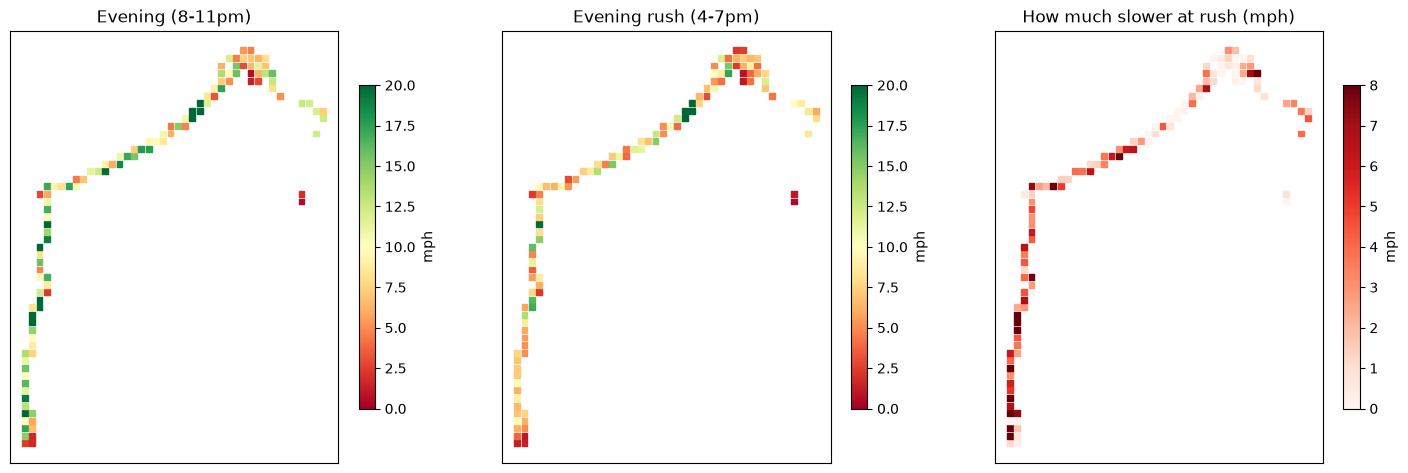

period     lat      lon  night  rush  drop
8       42.303 -71.1152   19.9   6.9  13.1
22      42.315 -71.1139   20.8   8.8  12.0
61      42.337 -71.0957   15.3   3.8  11.5
4       42.301 -71.1152   17.3   6.2  11.1
2       42.300 -71.1152   14.8   3.8  11.0
11      42.305 -71.1152   19.2   9.0  10.2
21      42.314 -71.1139   14.5   5.9   8.6
15      42.309 -71.1152   15.6   7.1   8.4
102     42.348 -71.0710   15.9   7.7   8.2
23      42.316 -71.1139   21.5  13.5   8.0


In [4]:
import matplotlib.pyplot as plt

grid = con.sql("""
    SELECT round(((lat + prev_lat) / 2) / 0.001) * 0.001 AS lat,
           round(((lon + prev_lon) / 2) / 0.0013) * 0.0013 AS lon,
           CASE WHEN hour(ts_local) BETWEEN 16 AND 18 THEN 'rush' ELSE 'night' END AS period,
           sum(miles) / sum(secs) * 3600 AS mph,
           count(*) AS pairs
    FROM r39
    WHERE dayofweek(ts_local) BETWEEN 1 AND 5
      AND (hour(ts_local) BETWEEN 16 AND 18 OR hour(ts_local) BETWEEN 20 AND 22)
    GROUP BY ALL
    HAVING count(*) >= 20
""").df()

wide = grid.pivot_table(index=["lat", "lon"], columns="period", values="mph").dropna().reset_index()
wide["drop"] = wide["night"] - wide["rush"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
panels = [("night", "Evening (8-11pm)", "RdYlGn", 0, 20),
          ("rush", "Evening rush (4-7pm)", "RdYlGn", 0, 20),
          ("drop", "How much slower at rush (mph)", "Reds", 0, 8)]
for ax, (col, title, cmap, lo, hi) in zip(axes, panels):
    sc = ax.scatter(wide["lon"], wide["lat"], c=wide[col], cmap=cmap,
                    vmin=lo, vmax=hi, s=18, marker="s")
    ax.set_title(title)
    ax.set_aspect(1.35)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc, ax=ax, shrink=0.7, label="mph")
plt.show()

print(wide.sort_values("drop", ascending=False).head(10)
      .round({"lat": 4, "lon": 4, "night": 1, "rush": 1, "drop": 1}))

Findings:
- The worst slowdowns are on Centre St in Jamaica Plain, a narrow two-lane street with parking on both sides and no bus lane:
  buses go from about 21 mph at night to under 9 at rush.
- Another hot spot sits at Forest Hills, but it's next to the terminal, so part of that is buses queuing to enter the busway,
  not street traffic. The citywide method (notebook 02) leaves out each trip's first and last stretch for this reason.
- Back Bay is slow all day, so a rush-vs-night comparison understates it.

The method works on one route. Notebook 02 scales it up to every route.